# E-Commerce Customer Segmentation 


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [23]:
df = pd.read_csv("customers_segments.csv")
df.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Sum,Segment
0,12346,326,12,77556.46,2,5,5,255,12,At Risk
1,12347,2,8,4921.53,5,4,5,545,14,Champions
2,12348,75,5,2019.40,3,4,4,344,11,Loyal Customers
3,12349,19,4,4428.69,5,3,5,535,13,Loyal Customers
4,12350,310,1,334.40,2,1,2,212,5,Hibernating


In [24]:
print( df.shape)

print(df.columns)

df.info()

(5878, 10)
Index(['Customer ID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score',
       'M_Score', 'RFM_Score', 'RFM_Sum', 'Segment'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 5878 entries, 0 to 5877
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Customer ID  5878 non-null   int64  
 1   Recency      5878 non-null   int64  
 2   Frequency    5878 non-null   int64  
 3   Monetary     5878 non-null   float64
 4   R_Score      5878 non-null   int64  
 5   F_Score      5878 non-null   int64  
 6   M_Score      5878 non-null   int64  
 7   RFM_Score    5878 non-null   int64  
 8   RFM_Sum      5878 non-null   int64  
 9   Segment      5878 non-null   str    
dtypes: float64(1), int64(8), str(1)
memory usage: 459.3 KB


In [25]:
print(df.isnull().sum())

Customer ID    0
Recency        0
Frequency      0
Monetary       0
R_Score        0
F_Score        0
M_Score        0
RFM_Score      0
RFM_Sum        0
Segment        0
dtype: int64


In [26]:
rfm_columns = ["Recency", "Frequency", "Monetary"]

analysis_df = df[["Customer ID"] + rfm_columns + ["Segment"]].copy()
analysis_df = analysis_df.replace([np.inf, -np.inf], np.nan)
analysis_df = analysis_df.dropna(subset=rfm_columns)
analysis_df = analysis_df[
    (analysis_df["Recency"] >= 0)
    & (analysis_df["Frequency"] > 0)
    & (analysis_df["Monetary"] > 0)
].reset_index(drop=True)

print("Customers available for clustering:", len(analysis_df))
analysis_df.head()

Customers available for clustering: 5878


,Customer ID,Recency,Frequency,Monetary,Segment
0,12346,326,12,77556.46,At Risk
1,12347,2,8,4921.53,Champions
2,12348,75,5,2019.40,Loyal Customers
3,12349,19,4,4428.69,Loyal Customers
4,12350,310,1,334.40,Hibernating


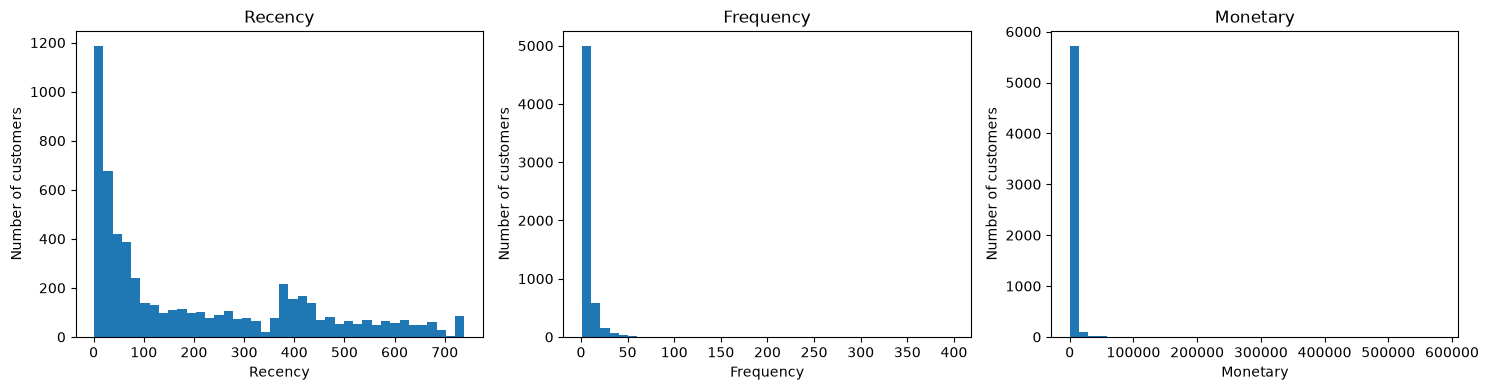

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, rfm_columns):
    ax.hist(analysis_df[column], bins=40)
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

In [28]:
rfm_log = np.log1p(analysis_df[rfm_columns])

scaler = StandardScaler()
scaled_rfm = scaler.fit_transform(rfm_log)

scaled_rfm_df = pd.DataFrame(scaled_rfm, columns=rfm_columns)
scaled_rfm_df.head()

,Recency,Frequency,Monetary
0,0.856701,1.254496,3.206219
1,-2.151979,0.800166,1.215993
2,-0.079138,0.299207,0.573185
3,-0.935308,0.073946,1.139846
4,0.824527,-1.058146,-0.723024


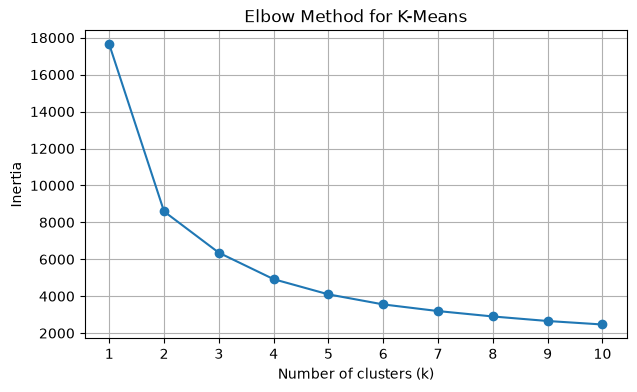

In [29]:
inertia_values = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaled_rfm)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

- X-axis — Number of clusters (K): How many customer groups we want K-Means to create.
- Y-axis — Inertia: How far customers are from the center of their assigned cluster. Lower inertia means customers are closer to their cluster centers.

## Step 9 — Apply K-Means

**What are we doing?** Asking K-Means to divide the customers into 4 groups.

**Why?** K-Means assigns each customer to the nearest of the chosen cluster centers. The cluster number (`0`, `1`, `2`, or `3`) is just an ID; it does not automatically mean good or bad customers.

If you decide on a different value of `k` after looking at the elbow plot, change `number_of_clusters` below.

In [30]:
number_of_clusters = 4

kmeans = KMeans(n_clusters=number_of_clusters, random_state=42, n_init=10)
analysis_df["KMeans_Cluster"] = kmeans.fit_predict(scaled_rfm)

print("Customers in each K-Means cluster:")
print(analysis_df["KMeans_Cluster"].value_counts().sort_index())

Customers in each K-Means cluster:
KMeans_Cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64


### View the number of customers in each K-Means cluster

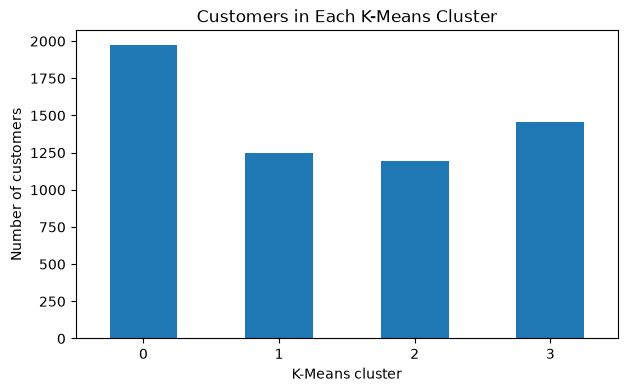

In [31]:
analysis_df["KMeans_Cluster"].value_counts().sort_index().plot(
    kind="bar", figsize=(7, 4)
)
plt.xlabel("K-Means cluster")
plt.ylabel("Number of customers")
plt.title("Customers in Each K-Means Cluster")
plt.xticks(rotation=0)
plt.show()

## Step 11 — Apply DBSCAN

**What are we doing?** Using DBSCAN to find dense groups of customers and mark points that do not fit a dense group as noise.

**Why?** Unlike K-Means, DBSCAN does not require us to choose the number of clusters in advance. It uses two main settings:
- `eps`: how close points must be to count as neighbours.
- `min_samples`: how many nearby points are needed to form a dense region.

We start with `eps=0.30` and `min_samples=10` on the scaled data. These are starting settings, not universal best values. DBSCAN results can change when these values change.

In [33]:
dbscan = DBSCAN(eps=0.30, min_samples=10)
analysis_df["DBSCAN_Cluster"] = dbscan.fit_predict(scaled_rfm)

print("Customers in each DBSCAN label:")
print(analysis_df["DBSCAN_Cluster"].value_counts().sort_index())

print("\nNumber of noise points:", (analysis_df["DBSCAN_Cluster"] == -1).sum())

Customers in each DBSCAN label:
DBSCAN_Cluster
-1     360
 0    3039
 1    1570
 2     909
Name: count, dtype: int64

Number of noise points: 360


## Step 12 — Reduce the data to two dimensions with PCA

In [35]:
pca = PCA(n_components=2)
pca_values = pca.fit_transform(scaled_rfm)

pca_df = pd.DataFrame(pca_values, columns=["PC1", "PC2"])
pca_df["KMeans_Cluster"] = analysis_df["KMeans_Cluster"].values
pca_df["DBSCAN_Cluster"] = analysis_df["DBSCAN_Cluster"].values


pca_df.head()

,PC1,PC2,KMeans_Cluster,DBSCAN_Cluster
0,2.277576,2.440652,2,-1
1,2.313905,-1.107910,2,0
2,0.570638,0.258820,3,0
3,1.205787,-0.308901,1,0
4,-1.505612,0.094624,0,1


### Plot PCA with the cluster labels

**What are we doing?** Showing the same PCA map twice: once coloured by K-Means clusters and once by DBSCAN labels.

**Why?** This gives us a visual way to inspect whether groups appear separated. The plot is a simplified view, so some overlap is normal and does not automatically mean the clustering failed.

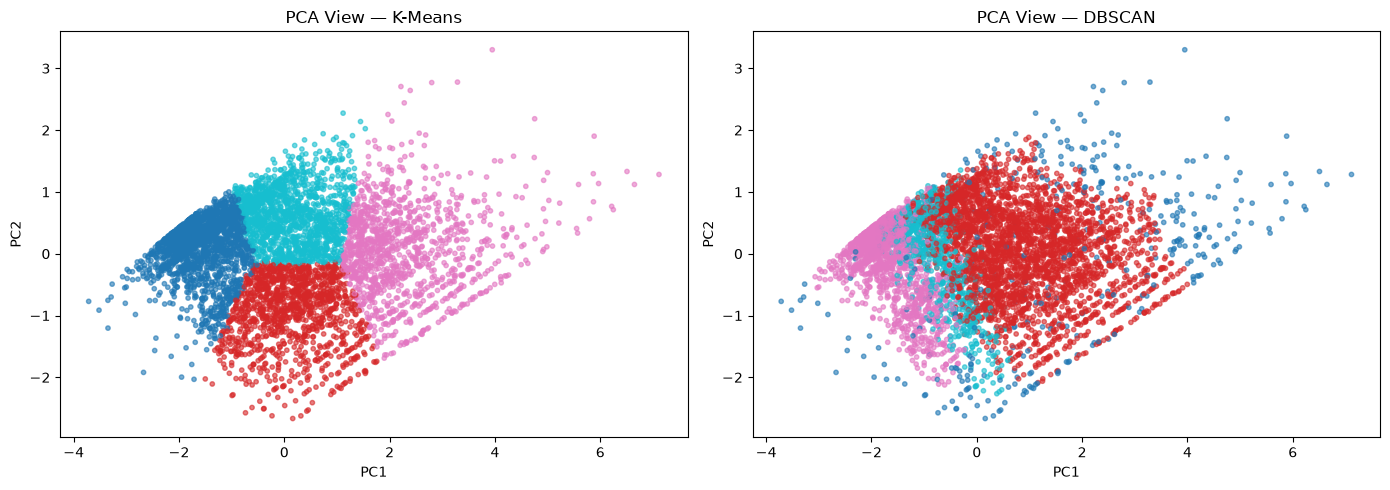

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    pca_df["PC1"], pca_df["PC2"],
    c=pca_df["KMeans_Cluster"], cmap="tab10", s=10, alpha=0.6
)
axes[0].set_title("PCA View — K-Means")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].scatter(
    pca_df["PC1"], pca_df["PC2"],
    c=pca_df["DBSCAN_Cluster"], cmap="tab10", s=10, alpha=0.6
)
axes[1].set_title("PCA View — DBSCAN")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

- X-axis — PC1: The first principal component, which captures the largest possible amount of variation in the data.
- Y-axis — PC2: The second principal component, which captures the next-largest amount of variation.
- Each dot: One customer.
- Different colours: Different cluster labels assigned by the algorithm.

## Step 13 — Visualize the clusters with t-SNE

**What are we doing?** Using t-SNE to create another 2D map of the customers from their scaled RFM values.

**Why?** t-SNE tries to keep customers that are similar in the original feature space near each other on the map. It can reveal local group patterns that are not obvious in a simple chart.

We use the scaled RFM data as input. PCA and t-SNE are two different visualization methods, so we do not need to feed the PCA plot into t-SNE. The axes in a t-SNE plot do not have a direct business meaning, and distances between far-away groups should be interpreted carefully.

In [37]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

tsne_values = tsne.fit_transform(scaled_rfm)
analysis_df["TSNE_1"] = tsne_values[:, 0]
analysis_df["TSNE_2"] = tsne_values[:, 1]

print("t-SNE coordinates created for", len(analysis_df), "customers")

t-SNE coordinates created for 5878 customers


### Plot the t-SNE results

**What are we doing?** Showing the t-SNE map coloured by each algorithm's cluster labels.

**Why?** It lets us visually compare the customer groups produced by K-Means and DBSCAN. It is a visualization, not a new clustering result.

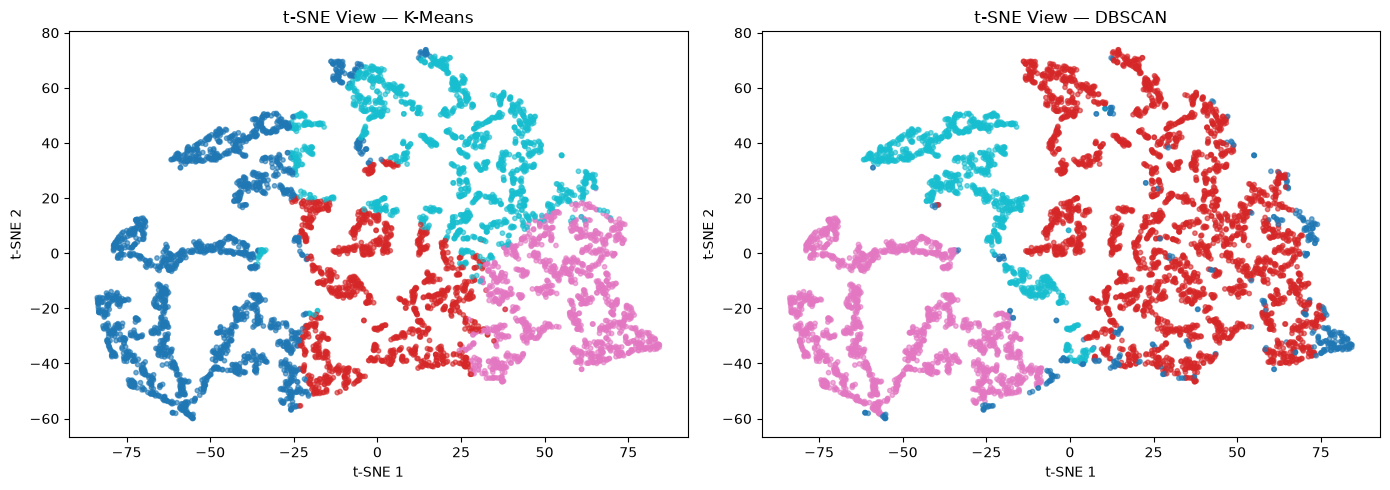

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    analysis_df["TSNE_1"], analysis_df["TSNE_2"],
    c=analysis_df["KMeans_Cluster"], cmap="tab10", s=10, alpha=0.6
)
axes[0].set_title("t-SNE View — K-Means")
axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")

axes[1].scatter(
    analysis_df["TSNE_1"], analysis_df["TSNE_2"],
    c=analysis_df["DBSCAN_Cluster"], cmap="tab10", s=10, alpha=0.6
)
axes[1].set_title("t-SNE View — DBSCAN")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

## Step 14 — Create customer personas and marketing actions

**What are we doing?** Giving the four K-Means clusters plain-language persona names and suggesting a marketing action for each one.

**Why?** Businesses need recommendations they can act on, not just cluster numbers. These names are based on the median RFM patterns in this dataset with `k=4`.

The labels below match the cluster profiles from this dataset and the settings above. If you change the dataset or the value of `k`, inspect the profile table again and update the mapping before using the personas.

In [39]:
persona_names = {
    0: "Hibernating / low-value customers",
    1: "Recent occasional buyers",
    2: "High-value active customers",
    3: "Cooling-off customers"
}

marketing_actions = {
    0: "Try a low-cost reactivation message or a relevant product reminder.",
    1: "Encourage a second purchase with recommendations or a small follow-up offer.",
    2: "Reward loyalty with member benefits, early access, or personalized offers.",
    3: "Try a win-back campaign and recommend products related to past purchases."
}

analysis_df["Marketing_Persona"] = analysis_df["KMeans_Cluster"].map(persona_names)
analysis_df["Suggested_Marketing_Action"] = analysis_df["KMeans_Cluster"].map(marketing_actions)

persona_summary = analysis_df.groupby(
    ["KMeans_Cluster", "Marketing_Persona"], as_index=False
).agg(
    Customer_Count=("Customer ID", "count"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Monetary=("Monetary", "median")
)

persona_summary["Suggested_Marketing_Action"] = persona_summary["KMeans_Cluster"].map(marketing_actions)
persona_summary

,KMeans_Cluster,Marketing_Persona,Customer_Count,Median_Recency,Median_Frequency,Median_Monetary,Suggested_Marketing_Action
0,0,Hibernating / low-value customers,1973,402.0,1.0,273.310,Try a low-cost reactivation message or a relev...
1,1,Recent occasional buyers,1250,24.0,3.0,734.115,Encourage a second purchase with recommendatio...
2,2,High-value active customers,1196,17.0,13.0,4986.115,"Reward loyalty with member benefits, early acc..."
3,3,Cooling-off customers,1459,186.0,4.0,1450.040,Try a win-back campaign and recommend products...
